# Speed check: SOG vs STW, zeros and resolution

Checks three claims from the inventory:

1. **Resolution:** `sog_kn` and `stw_kn` only have 154 and 184 distinct values, because they are logged in 0.1 kn steps.
2. **Zeros = ship lying still:** 0 is the most common value (18% of SOG, 7% of STW readings), and should mean the ship is in port or at anchor.
3. **SOG vs STW:** GPS speed over ground and speed-log speed through water differ by the current, but both should be 0 when the ship is still.

Signals are matched on the same 15 s moment (timestamps rounded to the nearest 15 s; median offset 0.01 s). Nothing is filtered or changed.

**Before running:** `python src/load_raw.py`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

PROCESSED = os.path.join("..", "data", "processed")
SIGNALS = ["sog_kn", "stw_kn", "shaft_rpm", "me_rpm", "heading_deg"]
raw = pd.read_parquet(os.path.join(PROCESSED, "raw_long"), columns=["time", "signal", "value"],
                      filters=[("signal", "in", SIGNALS)])
raw["slot"] = raw.time.dt.round("15s")
w = raw.groupby(["slot", "signal"], observed=True).value.mean().unstack()   # one row per 15 s moment
w.index = w.index.tz_convert(None)

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10})
print(f"{len(w):,} moments (15 s) with SOG, STW or shaft rpm; {w.index.min()} to {w.index.max()}")
print(w[SIGNALS[:3]].notna().sum().map("{:,}".format).to_string())

2,103,486 moments (15 s) with SOG, STW or shaft rpm; 2024-01-01 00:00:00 to 2025-01-31 23:56:45
signal
sog_kn       2,080,048
stw_kn       2,057,890
shaft_rpm    1,907,811


## 1. Resolution: are speeds really logged in 0.1 kn steps?

sog_kn: 2,080,101 readings, 154 distinct values, range 0.0 to 15.3 kn
   smallest step between distinct values: 0.100 kn | share of readings on the 0.1 kn grid: 100.00%
stw_kn: 2,057,942 readings, 184 distinct values, range -3.6 to 14.9 kn
   smallest step between distinct values: 0.100 kn | share of readings on the 0.1 kn grid: 100.00%


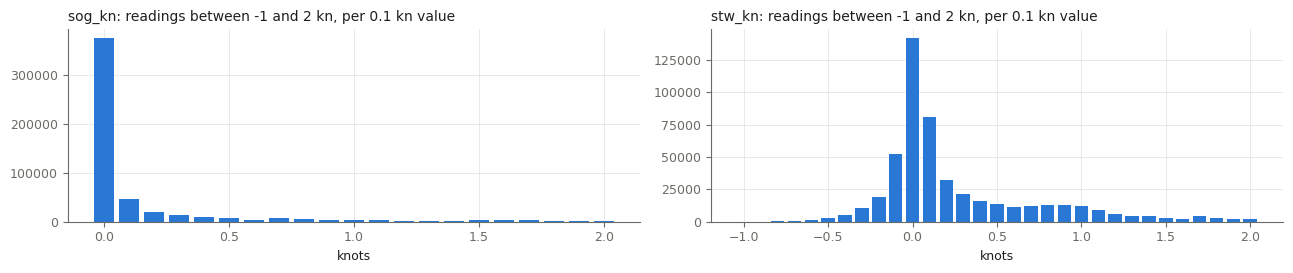

In [2]:
for s in ["sog_kn", "stw_kn"]:
    v = raw.loc[raw.signal == s, "value"].dropna()
    vals = np.sort(v.unique())
    steps = np.diff(vals)
    on_grid = np.isclose(v * 10, np.round(v * 10), atol=1e-6).mean()
    print(f"{s}: {len(v):,} readings, {len(vals)} distinct values, range {vals.min()} to {vals.max()} kn")
    print(f"   smallest step between distinct values: {steps.min():.3f} kn | share of readings on the 0.1 kn grid: {100 * on_grid:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 2.8), sharey=False)
for ax, s in zip(axes, ["sog_kn", "stw_kn"]):
    v = raw.loc[raw.signal == s, "value"]
    near = v[v.between(-1.05, 2.05)]
    counts = near.round(1).value_counts().sort_index()
    ax.bar(counts.index, counts.values, width=0.08, color=BLUE)
    ax.set_title(f"{s}: readings between -1 and 2 kn, per 0.1 kn value", loc="left", color=INK)
    ax.set_xlabel("knots")
fig.tight_layout(); plt.show()

## 2. Zeros: SOG and STW at the same moment

Each 15 s moment where both speeds exist gets one of four labels:

| Label | Meaning |
|---|---|
| **both 0** | ship lying still, as expected |
| **SOG 0, STW not 0** | GPS says still, speed log sees water moving: current or tide past a moored ship, or speed-log noise |
| **STW 0, SOG not 0** | GPS says moving, speed log reads 0: drifting with the current at low speed, or **speed log dead while sailing** if SOG is high |
| **both moving** | normal sailing or manoeuvring |

In [3]:
both = w.dropna(subset=["sog_kn", "stw_kn"])
sog0, stw0 = both.sog_kn == 0, both.stw_kn == 0
LABELS = ["both 0", "SOG 0, STW not 0", "STW 0, SOG not 0", "both moving"]
COLORS = dict(zip(LABELS, [BLUE, ORANGE, AQUA, YELLOW]))
cat = pd.Series(np.select([sog0 & stw0, sog0 & ~stw0, ~sog0 & stw0], LABELS[:3], LABELS[3]), index=both.index)

summary = pd.DataFrame({"moments": cat.value_counts().reindex(LABELS)})
summary["%"] = (100 * summary.moments / len(cat)).round(2)
summary["hours"] = (summary.moments * 15 / 3600).round(0)
print(f"moments with both SOG and STW: {len(both):,}  | only SOG: {(w.sog_kn.notna() & w.stw_kn.isna()).sum():,}"
      f"  | only STW: {(w.stw_kn.notna() & w.sog_kn.isna()).sum():,}")
summary

moments with both SOG and STW: 2,042,585  | only SOG: 37,463  | only STW: 15,305


,moments,%,hours
both 0,125335,6.14,522.0
"SOG 0, STW not 0",223527,10.94,931.0
"STW 0, SOG not 0",15894,0.78,66.0
both moving,1677829,82.14,6991.0


In [4]:
print("Speeds in the mixed cases (kn):")
for lab, col in [("SOG 0, STW not 0", "stw_kn"), ("STW 0, SOG not 0", "sog_kn")]:
    v = both.loc[cat == lab, col]
    print(f"  {lab}: {col} median {v.median():.2f}, p95 {v.quantile(0.95):.2f}, max {v.max():.2f}"
          f" | share above 3 kn: {100 * (v.abs() > 3).mean():.1f}%")
rpm = both.shaft_rpm
print("\nPropeller during each label (shaft rpm, where logged):")
print(pd.DataFrame({lab: {"rpm == 0 %": 100 * (rpm[cat == lab] == 0).mean(),
                          "median rpm": rpm[cat == lab].median()} for lab in LABELS}).T.round(1).to_string())

Speeds in the mixed cases (kn):
  SOG 0, STW not 0: stw_kn median 0.10, p95 1.90, max 2.80 | share above 3 kn: 0.0%
  STW 0, SOG not 0: sog_kn median 0.20, p95 1.10, max 9.70 | share above 3 kn: 0.1%

Propeller during each label (shaft rpm, where logged):


                  rpm == 0 %  median rpm
both 0                  71.9         0.0
SOG 0, STW not 0        83.1         0.0
STW 0, SOG not 0        95.5         0.0
both moving             17.5        78.7


## 3. Distribution over the year

Hours per day in each label. Days with no bar have no SOG/STW data at all (e.g. 24 Sep – 16 Oct).

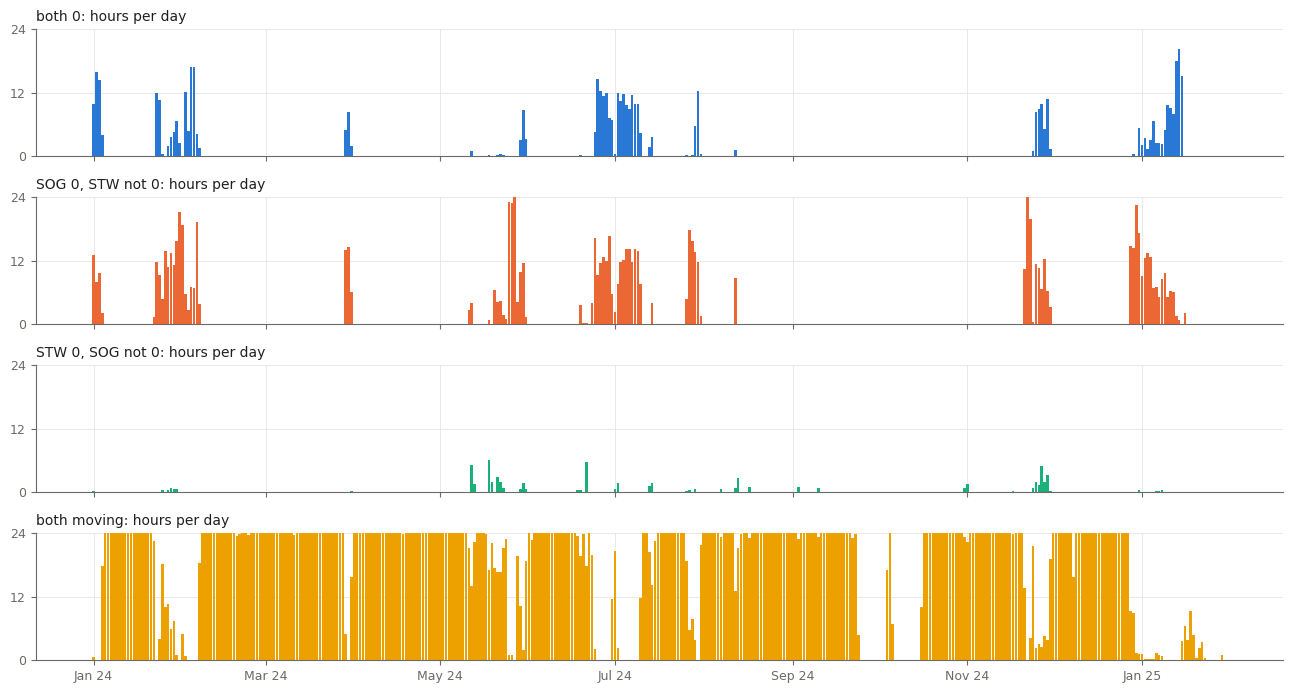

Hours per month


,both 0,"SOG 0, STW not 0","STW 0, SOG not 0",both moving
slot,,,,
2024-01,87,147,4,506
2024-02,57,64,0,551
2024-03,15,35,0,692
2024-04,0,0,0,720
2024-05,17,123,23,580
2024-06,70,92,7,549
2024-07,114,179,7,438
2024-08,1,9,5,729
2024-09,0,0,2,554


In [5]:
daily = (cat.groupby([cat.index.normalize(), cat]).size().unstack(fill_value=0).reindex(columns=LABELS, fill_value=0) * 15 / 3600)
full = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(full)

fig, axes = plt.subplots(len(LABELS), 1, figsize=(13, 7), sharex=True)
for ax, lab in zip(axes, LABELS):
    ax.bar(daily.index, daily[lab].fillna(0), width=0.9, color=COLORS[lab])
    ax.set_ylim(0, 24); ax.set_yticks([0, 12, 24])
    ax.set_title(f"{lab}: hours per day", loc="left", color=INK)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.tight_layout(); plt.show()

monthly = cat.groupby([cat.index.to_period("M"), cat]).size().unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
print("Hours per month")
(monthly * 15 / 3600).round(0).astype(int)

## 4. Stops: every period where SOG stays at 0

A stop is an unbroken run of SOG = 0 (a run ends when SOG is above 0 or there is no reading for more than 1 minute).
Long stops with the propeller stopped are port or anchor stays.

In [6]:
s = w.sog_kn.dropna()
new_run = (s != 0) | (s.index.to_series().diff() > pd.Timedelta("1min"))
run_id = new_run.cumsum()
zero = s == 0
runs = s[zero].groupby(run_id[zero]).agg(start=lambda x: x.index.min(), end=lambda x: x.index.max(), moments="size")
runs["hours"] = (runs.end - runs.start).dt.total_seconds() / 3600 + 15 / 3600
rpm_s = w.shaft_rpm
def rpm_stats(a, b):
    r = rpm_s.loc[a:b].dropna()          # Jan 2025 has no shaft data -> NaN, not 0%
    return (100 * (r == 0).mean(), r.median()) if len(r) else (np.nan, np.nan)
runs[["rpm_zero_%", "rpm_median"]] = [rpm_stats(a, b) for a, b in zip(runs.start, runs.end)]
runs["stw_median"] = [w.stw_kn.loc[a:b].median() for a, b in zip(runs.start, runs.end)]

bins = [0, 1 / 60, 0.25, 1, 6, 36, 1e9]
names = ["< 1 min", "1–15 min", "15 min–1 h", "1–6 h", "6–36 h", "> 36 h"]
runs["length"] = pd.cut(runs.hours, bins, labels=names, right=False)
print(f"{len(runs):,} runs of SOG = 0, total {runs.hours.sum():,.0f} h")
display(runs.groupby("length", observed=False).agg(runs=("hours", "size"), total_hours=("hours", "sum")).round(1))

long = runs[runs.hours >= 6].sort_values("start")
print(f"Stops of 6 h or more: {len(long)}")
long[["start", "end", "hours", "rpm_zero_%", "rpm_median", "stw_median"]].round(1).reset_index(drop=True)

6,827 runs of SOG = 0, total 1,564 h


,runs,total_hours
length,,
< 1 min,4478,28.0
1–15 min,1913,110.8
15 min–1 h,281,143.9
1–6 h,126,290.6
6–36 h,20,243.7
> 36 h,9,747.3


Stops of 6 h or more: 29


,start,end,hours,rpm_zero_%,rpm_median,stw_median
0,2024-01-01 23:33:45,2024-01-04 00:10:15,48.6,100.0,0.0,0.0
1,2024-01-23 03:33:00,2024-01-24 19:55:45,40.4,99.8,0.0,0.0
2,2024-01-30 08:30:30,2024-01-30 16:22:30,7.9,100.0,0.0,-0.1
3,2024-01-30 23:57:15,2024-01-31 10:02:15,10.1,100.0,0.0,0.1
4,2024-01-31 10:51:45,2024-02-01 11:10:15,24.3,100.0,0.0,0.5
5,2024-02-02 00:59:00,2024-02-02 15:54:00,14.9,100.0,0.0,0.0
6,2024-02-03 16:44:15,2024-02-04 19:39:00,26.9,100.0,0.0,0.0
7,2024-02-04 19:40:15,2024-02-06 22:48:00,51.1,100.0,0.0,0.0
8,2024-03-29 04:59:15,2024-03-30 01:25:15,20.4,100.0,0.0,-0.1
9,2024-03-30 08:11:00,2024-03-31 05:08:45,21.0,100.0,0.0,0.0


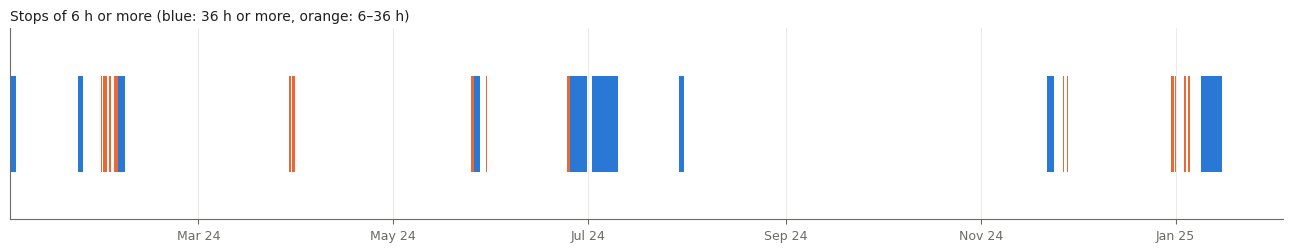

In [7]:
fig, ax = plt.subplots(figsize=(13, 2.6))
for _, r in long.iterrows():
    ax.barh(0, (r.end - r.start).total_seconds() / 86400, left=r.start, height=0.6,
            color=BLUE if r.hours >= 36 else ORANGE)
ax.set_yticks([]); ax.set_ylim(-0.6, 0.6)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_title("Stops of 6 h or more (blue: 36 h or more, orange: 6–36 h)", loc="left", color=INK)
fig.tight_layout(); plt.show()

## 5. Speed log dead while sailing?

Moments where the speed log reads exactly 0 while GPS says the ship moves faster than 3 kn. A real ship at that speed always has water flowing past, so these are speed-log faults.

In [8]:
dead = both[(both.stw_kn == 0) & (both.sog_kn > 3)]
print(f"{len(dead):,} moments ({len(dead) * 15 / 3600:.1f} h) with STW = 0 and SOG > 3 kn")
if len(dead):
    print("Per day (hours):")
    print((dead.groupby(dead.index.normalize()).size() * 15 / 3600).round(2).loc[lambda x: x > 0].to_string())

9 moments (0.0 h) with STW = 0 and SOG > 3 kn
Per day (hours):
slot
2024-05-29    0.01
2024-11-20    0.02
2024-11-24    0.01


## Findings

Questions to answer from the results:
- Is the 0.1 kn resolution confirmed for both speeds?
- What share of zeros are real stops (both 0, propeller stopped)?
- How many hours fall in the mixed cases, and are any of them faults (section 5)?
- Do the long stops match port calls in the noon reports?

## 6. Time split: at port, warming up, anchored

Every 15 s moment with a GPS speed gets one label:

| Label | Rule |
|---|---|
| **At port** | inside a port stop, propeller not turning |
| **At port, warming up** | inside a port stop, propeller turning (ship tied up, engine and propeller running) |
| **Anchored / drifting** | inside an anchor stop |
| **Sailing / manoeuvring** | everything else |

**Stop** = unbroken period with SOG below 0.5 kn lasting at least 2 h (an anchored ship still moves a little, so not exactly 0).
**Port or anchor:** a ship moored at a berth keeps its heading; an anchored ship swings around its anchor. A stop is **port** if the heading spread (circular standard deviation) stays below 5°, otherwise **anchor**. At the berth the spread is 0.1–0.7°; at anchor 15–130°.
**Propeller turning:** shaft rpm > 0; Jan 2025 has no shaft rpm, so engine rpm (`me_rpm`) is used there (same thing on this ship, direct drive).

The three thresholds are set at the top of the cell so the team can change them. Hours with no GPS data (e.g. 24 Sep – 16 Oct) are not counted.

In [9]:
STOP_SOG_KN = 0.5      # below this the ship counts as stopped
STOP_MIN_H = 2         # shorter slow periods count as manoeuvring
PORT_HEADING_DEG = 5   # heading spread below this = moored at a berth

sog = w.sog_kn.dropna()
slow = sog < STOP_SOG_KN
new = ~slow | (sog.index.to_series().diff() > pd.Timedelta("1min"))
rid = new.cumsum()

def heading_spread(h):
    h = np.deg2rad(h.dropna())
    if h.empty:
        return np.nan
    r = np.hypot(np.cos(h).mean(), np.sin(h).mean())
    return np.degrees(np.sqrt(-2 * np.log(max(r, 1e-12))))

stops = sog[slow].groupby(rid[slow]).apply(lambda x: pd.Series({"start": x.index.min(), "end": x.index.max()})).unstack()
stops["hours"] = (stops.end - stops.start).dt.total_seconds() / 3600 + 15 / 3600
stops = stops[stops.hours >= STOP_MIN_H].copy()
stops["heading_spread"] = [heading_spread(w.heading_deg.loc[a:b]) for a, b in zip(stops.start, stops.end)]
stops["type"] = np.where(stops.heading_spread < PORT_HEADING_DEG, "port", "anchor")

rpm = w.shaft_rpm.fillna(w.me_rpm).reindex(sog.index)
stop_type = pd.Series(rid[slow].map(stops.type), index=sog[slow].index).reindex(sog.index)
label = pd.Series("Sailing / manoeuvring", index=sog.index)
label[stop_type == "anchor"] = "Anchored / drifting"
label[(stop_type == "port") & ~(rpm > 0)] = "At port"
label[(stop_type == "port") & (rpm > 0)] = "At port, warming up"

ORDER = ["At port", "At port, warming up", "Anchored / drifting", "Sailing / manoeuvring"]
split = pd.DataFrame({"hours": (label.value_counts() * 15 / 3600).reindex(ORDER).fillna(0)})
split["%"] = 100 * split.hours / split.hours.sum()
print(f"{len(stops)} stops of {STOP_MIN_H} h or more: {(stops.type == 'port').sum()} port, {(stops.type == 'anchor').sum()} anchor")
print(f"time covered: {split.hours.sum():,.0f} h")
split.round(1)

68 stops of 2 h or more: 22 port, 46 anchor
time covered: 8,667 h


,hours,%
At port,937.1,10.8
"At port, warming up",0.6,0.0
Anchored / drifting,744.0,8.6
Sailing / manoeuvring,6985.3,80.6


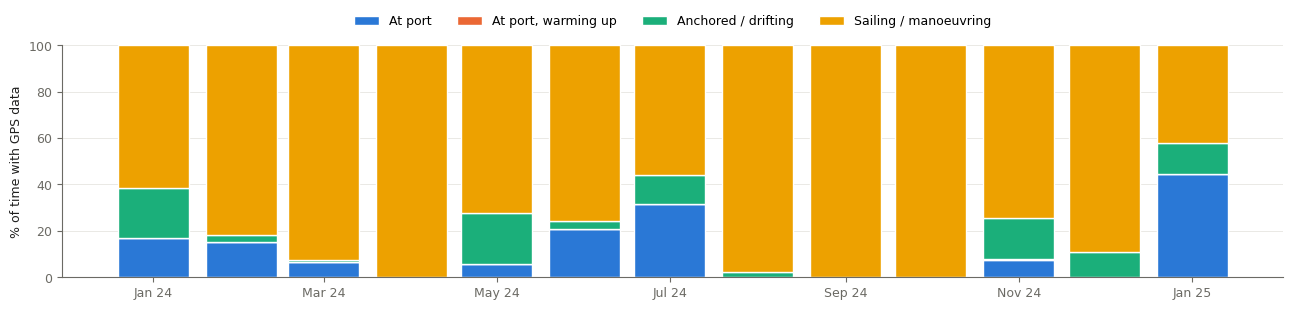

% of time per month


,At port,"At port, warming up",Anchored / drifting,Sailing / manoeuvring
slot,,,,
2024-01,16.7,0.0,21.6,61.7
2024-02,15.3,0.0,2.9,81.8
2024-03,6.5,0.0,0.8,92.7
2024-04,0.0,0.0,0.0,100.0
2024-05,5.6,0.0,21.8,72.5
2024-06,20.9,0.0,3.3,75.9
2024-07,31.5,0.0,12.5,56.0
2024-08,0.0,0.0,2.2,97.8
2024-09,0.0,0.0,0.0,100.0


In [10]:
monthly = (label.groupby([label.index.to_period("M"), label]).size().unstack(fill_value=0).reindex(columns=ORDER, fill_value=0))
monthly_pct = 100 * monthly.div(monthly.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(13, 3.2))
bottom = np.zeros(len(monthly_pct))
x = monthly_pct.index.to_timestamp()
for lab, color in zip(ORDER, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.bar(x, monthly_pct[lab], width=25, bottom=bottom, color=color, label=lab, edgecolor="white", linewidth=1)
    bottom += monthly_pct[lab].values
ax.set_ylim(0, 100); ax.set_ylabel("% of time with GPS data")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.18))
fig.tight_layout(); plt.show()
print("% of time per month")
monthly_pct.round(1)

In [11]:
print("All stops with their label (check the borderline ones by hand):")
stops[["start", "end", "hours", "heading_spread", "type"]].round(1).reset_index(drop=True)

All stops with their label (check the borderline ones by hand):


,start,end,hours,heading_spread,type
0,2024-01-01 00:00:00,2024-01-04 06:17:30,78.3,0.1,port
1,2024-01-22 05:18:30,2024-01-22 17:52:30,12.6,9.6,anchor
2,2024-01-23 00:03:00,2024-01-24 20:00:45,44.0,2.0,port
3,2024-01-25 03:49:30,2024-01-25 06:57:30,3.1,7.4,anchor
4,2024-01-25 07:37:30,2024-01-25 09:39:45,2.0,4.9,port
...,...,...,...,...,...
63,2025-01-04 11:45:00,2025-01-04 14:38:45,2.9,3.4,port
64,2025-01-04 14:45:00,2025-01-05 08:07:45,17.4,20.5,anchor
65,2025-01-05 08:22:00,2025-01-05 10:47:45,2.4,6.5,anchor
66,2025-01-05 14:28:00,2025-01-05 16:47:45,2.3,5.3,anchor
